,Inception,Interstellar,Titanic,Avatar,Joker,The Notebook,Avengers,Frozen,The Dark Knight,Toy Story
User 1,5,5,0,4,5,0,4,0,5,0
User 2,4,5,0,0,4,0,5,0,4,0
User 3,0,0,5,5,0,5,0,4,0,4
User 4,5,4,0,0,4,0,5,0,5,0
User 5,0,0,5,4,0,5,0,5,0,5
User 6,4,5,0,0,5,0,4,0,5,0
User 7,0,0,4,5,0,4,0,5,0,4
User 8,5,4,0,0,4,0,5,0,4,0


Top 5 Recommended Movies for User 1


,Predicted Rating
Frozen,4.644539
Titanic,4.628575
The Notebook,4.628575
Toy Story,4.273114


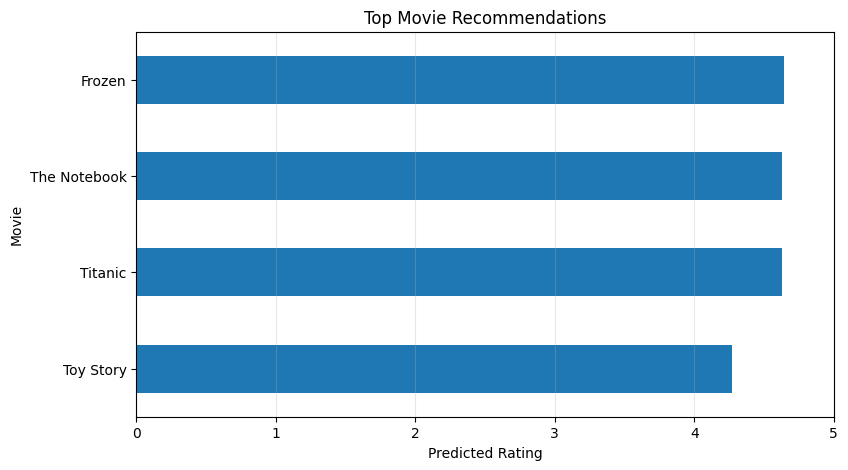

Recommendation System Completed Successfully!


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity

ratings = {
    "Inception": [5, 4, 0, 5, 0, 4, 0, 5],
    "Interstellar": [5, 5, 0, 4, 0, 5, 0, 4],
    "Titanic": [0, 0, 5, 0, 5, 0, 4, 0],
    "Avatar": [4, 0, 5, 0, 4, 0, 5, 0],
    "Joker": [5, 4, 0, 4, 0, 5, 0, 4],
    "The Notebook": [0, 0, 5, 0, 5, 0, 4, 0],
    "Avengers": [4, 5, 0, 5, 0, 4, 0, 5],
    "Frozen": [0, 0, 4, 0, 5, 0, 5, 0],
    "The Dark Knight": [5, 4, 0, 5, 0, 5, 0, 4],
    "Toy Story": [0, 0, 4, 0, 5, 0, 4, 0]
}

df = pd.DataFrame(
    ratings,
    index=[f"User {i}" for i in range(1, 9)]
)

display(df)

similarity = cosine_similarity(df)

similarity_df = pd.DataFrame(
    similarity,
    index=df.index,
    columns=df.index
)

target_user = "User 1"

user_similarity = similarity_df.loc[target_user].drop(target_user)

unwatched = df.loc[target_user][df.loc[target_user] == 0].index

recommendations = {}

for movie in unwatched:
    movie_ratings = df.loc[user_similarity.index, movie]
    valid_users = movie_ratings[movie_ratings > 0]

    if len(valid_users) > 0:
        weights = user_similarity.loc[valid_users.index]
        score = np.average(valid_users, weights=weights)
        recommendations[movie] = score

recommendations = pd.Series(recommendations).sort_values(
    ascending=False
)

print("Top 5 Recommended Movies for", target_user)

display(
    recommendations.head(5).rename(
        "Predicted Rating"
    ).to_frame()
)

if len(recommendations) > 0:
    recommendations.head(5).sort_values().plot(
        kind="barh",
        figsize=(9, 5)
    )

    plt.title("Top Movie Recommendations")
    plt.xlabel("Predicted Rating")
    plt.ylabel("Movie")
    plt.xlim(0, 5)
    plt.grid(axis="x", alpha=0.3)
    plt.show()

print("Recommendation System Completed Successfully!")